# Visualisasi Data Transaksi POS dengan Matplotlib
Dataset: `data/paket_a_transaksi_pos_2024_2025.csv`

1. Penjualan per bulan tahun 2025
2. 10 produk terlaris tahun 2025
3. Proporsi transaksi berhasil vs gagal/batal tahun 2025
4. Hubungan jumlah beli dengan diskon

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv('paket_a_transaksi_pos_2024_2025.csv')
df.shape

(5030, 9)

## Persiapan data
Pembersihan sama seperti tugas sebelumnya, ditambah konversi kolom `tanggal` yang formatnya campur (`2025-06-02`, `26/03/2025`, `23-12-2024`).

In [3]:
# Harga: titik ribuan dihapus, koma desimal -> titik
h = df['harga_satuan'].astype(str).str.strip()
h = h.str.replace(r'^(\d{1,3})\.(\d{3})$', r'\1\2', regex=True).str.replace(',', '.', regex=False)
df['harga_satuan'] = h.astype(float)

# Jumlah negatif -> positif
df['jumlah'] = df['jumlah'].abs()

# Tanggal: coba tiap format secara eksplisit
t = df['tanggal'].astype(str)
df['tanggal'] = (pd.to_datetime(t, format='%Y-%m-%d', errors='coerce')
                 .fillna(pd.to_datetime(t, format='%d/%m/%Y', errors='coerce'))
                 .fillna(pd.to_datetime(t, format='%d-%m-%Y', errors='coerce')))
print('Tanggal gagal diparse:', df['tanggal'].isna().sum())

# Omzet bersih (sama seperti Task 2)
df['Total_Kotor'] = df['harga_satuan'] * df['jumlah']
df['Total_Bersih'] = (df['Total_Kotor'] * (1 - df['diskon_persen'] / 100)) * 1.11

df_2025 = df[df['tanggal'].dt.year == 2025]
selesai_2025 = df_2025[df_2025['status'] == 'SELESAI']
print('Transaksi 2025:', len(df_2025), '| berstatus SELESAI:', len(selesai_2025))

Tanggal gagal diparse: 0
Transaksi 2025: 2523 | berstatus SELESAI: 2385


# Bagian 1 — Penjualan per bulan tahun 2025
Penjualan = total `Total_Bersih` transaksi berstatus **SELESAI** (BATAL dan RETUR tidak dihitung).

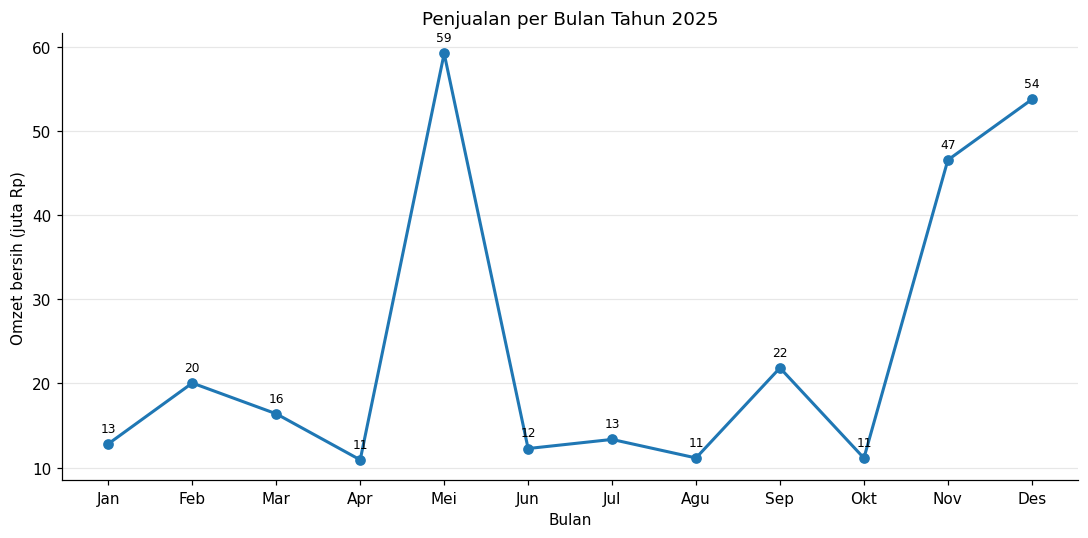

In [4]:
bulan = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
per_bulan = (selesai_2025.groupby(selesai_2025['tanggal'].dt.month)['Total_Bersih']
             .sum().reindex(range(1, 13), fill_value=0) / 1e6)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(bulan, per_bulan.values, marker='o', color='#1f77b4', linewidth=2)
for x, y in zip(bulan, per_bulan.values):
    ax.annotate(f'{y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
ax.set_title('Penjualan per Bulan Tahun 2025')
ax.set_xlabel('Bulan')
ax.set_ylabel('Omzet bersih (juta Rp)')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()

# Bagian 2 — 10 produk terlaris tahun 2025
Terlaris diukur dari **total unit terjual** (`jumlah`) pada transaksi SELESAI.

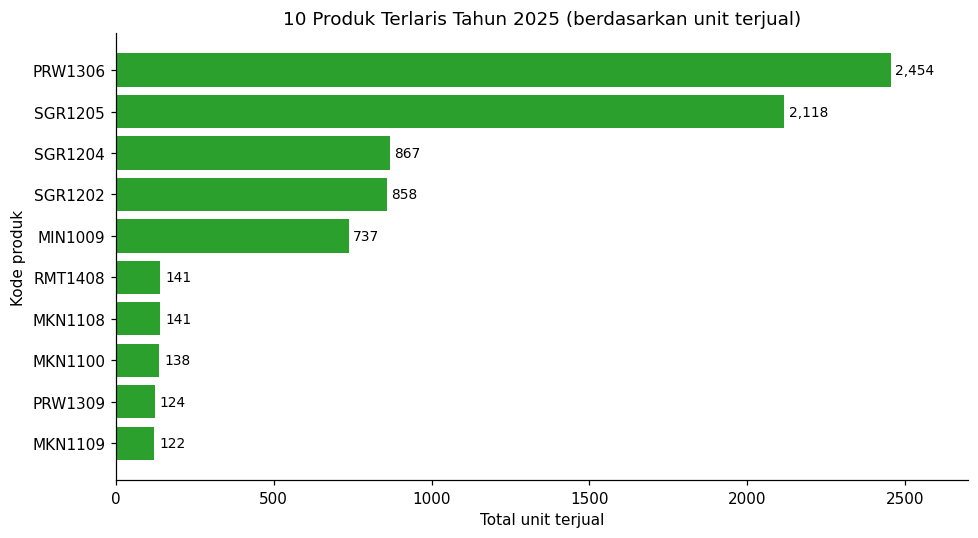

,jumlah
kode_produk,
PRW1306,2454
SGR1205,2118
SGR1204,867
SGR1202,858
MIN1009,737
MKN1108,141
RMT1408,141
MKN1100,138
PRW1309,124


In [5]:
top10 = (selesai_2025.groupby('kode_produk')['jumlah'].sum()
         .nlargest(10).sort_values())

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top10.index, top10.values, color='#2ca02c')
ax.bar_label(bars, fmt='{:,.0f}', padding=3, fontsize=9)
ax.set_title('10 Produk Terlaris Tahun 2025 (berdasarkan unit terjual)')
ax.set_xlabel('Total unit terjual')
ax.set_ylabel('Kode produk')
ax.margins(x=0.1)
fig.tight_layout()
plt.show()
top10.sort_values(ascending=False)

# Bagian 3 — Proporsi transaksi berhasil vs gagal/batal tahun 2025
Berhasil = `SELESAI`. Gagal/batal = `BATAL` dan `RETUR`. Ubah variabel `gagal` jika RETUR tidak ingin dimasukkan.

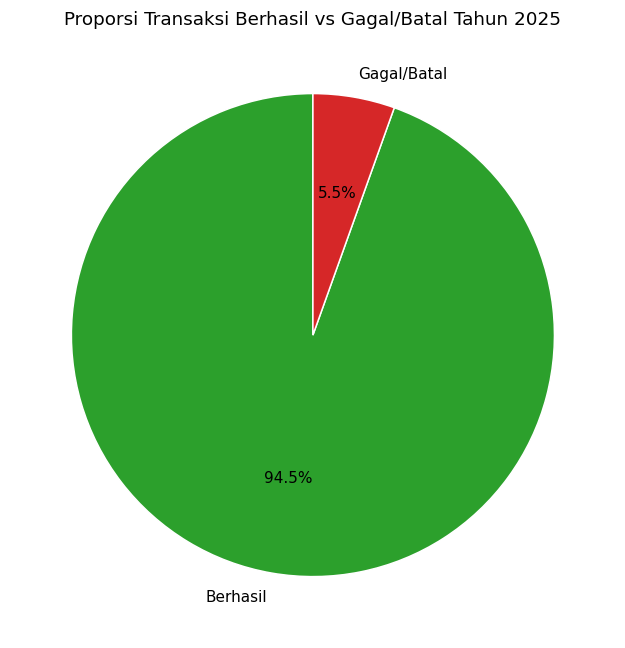

status
SELESAI    2385
BATAL        89
RETUR        49
Name: count, dtype: int64


,count
Berhasil,2385
Gagal/Batal,138


In [6]:
gagal = ['BATAL', 'RETUR']
kategori = np.where(df_2025['status'] == 'SELESAI', 'Berhasil',
           np.where(df_2025['status'].isin(gagal), 'Gagal/Batal', 'Lainnya'))
proporsi = pd.Series(kategori).value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(proporsi.values, labels=proporsi.index, autopct='%1.1f%%', startangle=90,
       colors=['#2ca02c', '#d62728', '#7f7f7f'][:len(proporsi)],
       wedgeprops={'edgecolor': 'white'})
ax.set_title('Proporsi Transaksi Berhasil vs Gagal/Batal Tahun 2025')
fig.tight_layout()
plt.show()
print(df_2025['status'].value_counts())
proporsi

# Bagian 4 — Hubungan jumlah beli dengan diskon
Memakai transaksi SELESAI tahun 2024–2025. Jumlah beli sangat condong ke kanan (ada transaksi ribuan unit), jadi sumbu y dibuat skala log dan perbandingan memakai **median** di samping rata-rata.

Korelasi Spearman diskon vs jumlah: -0.008


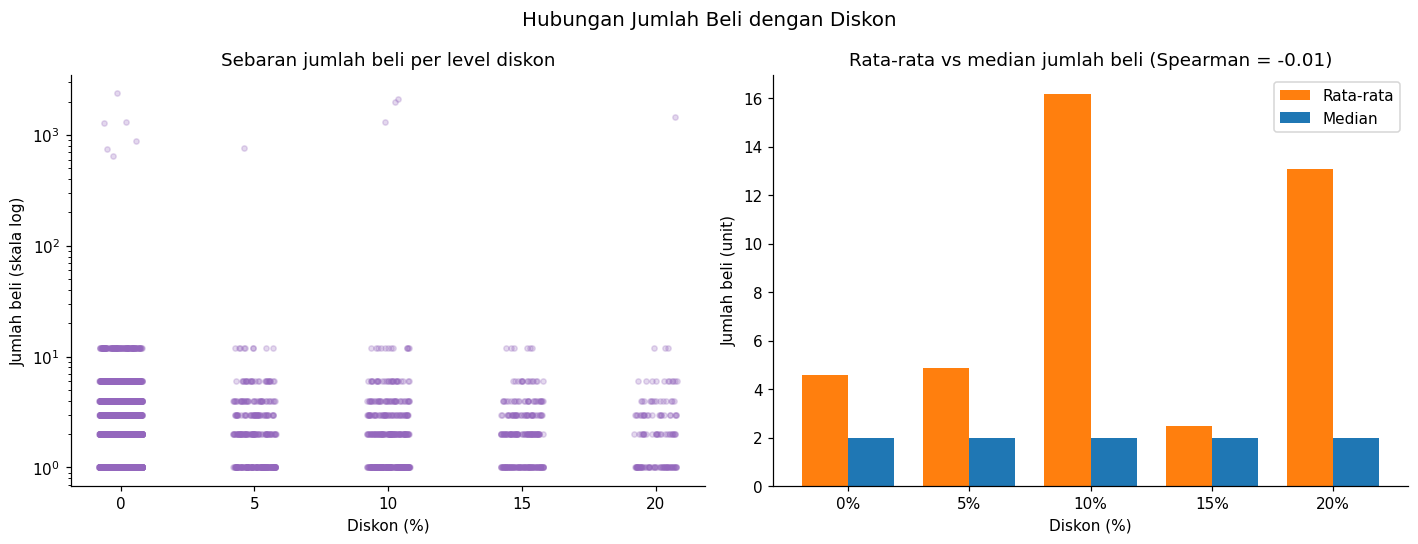

,mean,median
diskon_persen,,
0,4.57,2.0
5,4.89,2.0
10,16.16,2.0
15,2.47,2.0
20,13.08,2.0


In [7]:
sel = df[df['status'] == 'SELESAI']
rho = sel['diskon_persen'].corr(sel['jumlah'], method='spearman')
print(f'Korelasi Spearman diskon vs jumlah: {rho:.3f}')

levels = sorted(sel['diskon_persen'].unique())
ringkas = sel.groupby('diskon_persen')['jumlah'].agg(['mean', 'median'])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# kiri: scatter dengan jitter horizontal
rng = np.random.default_rng(42)
axes[0].scatter(sel['diskon_persen'] + rng.uniform(-0.8, 0.8, len(sel)), sel['jumlah'],
                alpha=0.25, s=12, color='#9467bd')
axes[0].set_yscale('log')
axes[0].set_xticks(levels)
axes[0].set_title('Sebaran jumlah beli per level diskon')
axes[0].set_xlabel('Diskon (%)')
axes[0].set_ylabel('Jumlah beli (skala log)')

# kanan: rata-rata vs median
x = np.arange(len(levels)); w = 0.38
axes[1].bar(x - w/2, ringkas['mean'], w, label='Rata-rata', color='#ff7f0e')
axes[1].bar(x + w/2, ringkas['median'], w, label='Median', color='#1f77b4')
axes[1].set_xticks(x); axes[1].set_xticklabels([f'{l}%' for l in levels])
axes[1].set_title(f'Rata-rata vs median jumlah beli (Spearman = {rho:.2f})')
axes[1].set_xlabel('Diskon (%)')
axes[1].set_ylabel('Jumlah beli (unit)')
axes[1].legend()

fig.suptitle('Hubungan Jumlah Beli dengan Diskon', fontsize=13)
fig.tight_layout()
plt.show()
ringkas.round(2)